# Early Time-Series Crop Classification in the Nile Delta
## Data Understanding, Cleaning, Outliers and Exploratory Analysis



The dataset describes about one million 10 m pixels of farmland in two districts of the Nile Delta, Zankalon (ZAN) and Sidi Ghazi (SGZ). Each pixel is followed through a growing season with Sentinel-2 satellite images, and labelled with the crop that the FAO WaPOR crop type map gives it.

| Part | Topic |
|---|---|
| 1 | Data Understanding |
| 2 | Data Cleaning |
| 3 | Outliers |
| 4 | Exploratory Analysis |
| 5 | Summary |

---
# Library

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

---
# 1. Data Understanding

## Read Data
The data is stored in five files with the same columns, one for each district and season. They are stacked into one table. The column `label_doubt` comes from the sample table and is needed in the cleaning part.

In [2]:
path = "../research/data/dataset/csv/"
files = ["ZAN_W2324", "ZAN_S2024", "SGZ_S2023", "SGZ_W2324", "SGZ_S2024"]

df = pd.concat([pd.read_csv(f"{path}{f}_timeseries.csv", parse_dates=["date"]) for f in files], ignore_index=True)

labels = pd.read_csv(path + "samples.csv", usecols=["sample_id", "label_doubt"])
df = df.merge(labels, on="sample_id")
df.head()

,sample_id,pixel_id,region,season,dekad,date,n_clear,ndvi,evi,ndwi,savi,gndvi,crop,label_doubt
0,0,131130657,ZAN,W2324,1,2023-10-01,1,0.4612,0.3093,0.0597,0.3236,0.5150,wheat,False
1,0,131130657,ZAN,W2324,2,2023-10-11,2,0.2262,0.1698,-0.1278,0.1743,0.3697,wheat,False
2,0,131130657,ZAN,W2324,3,2023-10-21,1,0.2782,0.1745,-0.0382,0.1814,0.4200,wheat,False
3,0,131130657,ZAN,W2324,4,2023-11-01,2,0.5558,0.3389,0.1404,0.3393,0.5522,wheat,False
4,0,131130657,ZAN,W2324,5,2023-11-11,1,0.4338,0.2415,-0.0169,0.2311,0.4527,wheat,False


| Column | Meaning |
|---|---|
| `sample_id` | one pixel in one season |
| `pixel_id` | the pixel itself (a pixel can appear in more than one season) |
| `region` | ZAN = Zankalon, SGZ = Sidi Ghazi |
| `season` | W2324 = winter 2023-24, S2023 and S2024 = summer |
| `dekad` | number of the 10-day period inside the season |
| `date` | first day of the period |
| `n_clear` | cloud-free satellite passes in the period (0 = the value was interpolated) |
| `ndvi`, `evi`, `ndwi`, `savi`, `gndvi` | vegetation indices computed from the satellite bands |
| `crop` | the class to predict |
| `label_doubt` | True when the class name does not fit how the pixels behave |

## Random Sample of Data

In [3]:
df.sample(5, random_state=42)

,sample_id,pixel_id,region,season,dekad,date,n_clear,ndvi,evi,ndwi,savi,gndvi,crop,label_doubt
18925403,917444,220971629,SGZ,W2324,6,2023-11-21,2,0.1931,0.0994,-0.0457,0.1047,0.3307,medicinal_plants,True
12074659,623758,214550645,SGZ,S2023,8,2023-07-11,2,0.8601,0.8025,0.4219,0.6891,0.7071,cotton,False
20688022,1003113,217060864,SGZ,S2024,17,2024-10-11,2,0.3571,0.1864,0.1025,0.1718,0.3406,rice,False
12275730,634991,207241589,SGZ,S2023,1,2023-05-01,0,0.2039,0.0796,0.2984,0.0758,0.1109,water,False
4371905,193869,126900992,ZAN,W2324,18,2024-03-21,0,0.6377,0.3283,0.1926,0.3328,0.5997,orchards,False


## Size of Data

In [4]:
print("Rows, columns:", df.shape)
print("Samples:", df["sample_id"].nunique())

Rows, columns: (22589094, 14)


Samples: 1074827


A **sample** is one pixel in one season. It has one **row** for every 10-day period: 24 rows in a winter season and 18 in a summer season. This is why one million samples give 22.6 million rows.

## Information of Data

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 22589094 entries, 0 to 22589093
Data columns (total 14 columns):
 #   Column       Dtype         
---  ------       -----         
 0   sample_id    int64         
 1   pixel_id     int64         
 2   region       str           
 3   season       str           
 4   dekad        int64         
 5   date         datetime64[us]
 6   n_clear      int64         
 7   ndvi         float64       
 8   evi          float64       
 9   ndwi         float64       
 10  savi         float64       
 11  gndvi        float64       
 12  crop         str           
 13  label_doubt  bool          
dtypes: bool(1), datetime64[us](1), float64(5), int64(4), str(3)
memory usage: 2.5 GB


## Check Description

In [6]:
indices = ["ndvi", "evi", "ndwi", "savi", "gndvi"]
df[indices + ["n_clear"]].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
ndvi,22589094.0,0.512,0.284,-1.00,0.233,0.543,0.779,1.000
evi,22589094.0,0.371,0.266,-1.00,0.129,0.324,0.590,1.000
ndwi,22589094.0,0.176,0.215,-1.00,-0.010,0.178,0.358,1.000
savi,22589094.0,0.337,0.220,-0.33,0.131,0.316,0.530,0.931
gndvi,22589094.0,0.506,0.210,-1.00,0.336,0.535,0.684,1.000
n_clear,22589094.0,1.348,0.768,0.00,1.000,1.000,2.000,3.000


The five indices are limited to the range -1 to 1. Half of the NDVI values lie between 0.23 and 0.78, the range from bare soil to a dense green crop. A period has between 0 and 3 clear passes.

## Number of Unique Values

In [7]:
df.nunique()

sample_id      1074827
pixel_id        993610
region               2
season               3
dekad               24
date                54
n_clear              4
ndvi             19217
evi              11395
ndwi             18498
savi             10402
gndvi            19070
crop                16
label_doubt          2
dtype: int64

## Check Balance Of Data
The balance is counted on samples, not rows, so a winter sample does not weigh more than a summer one.

In [8]:
samples = df.drop_duplicates("sample_id")
samples["crop"].value_counts()

crop
rice                174824
cotton              125994
orchards            117254
clover              115457
wheat               115309
vegetables          106165
maize                78921
sugarbeet            71149
medicinal_plants     57631
built_up             34870
water                25976
flax                 18951
bare_soil            16308
beans                12663
roads                 3340
others                  15
Name: count, dtype: int64

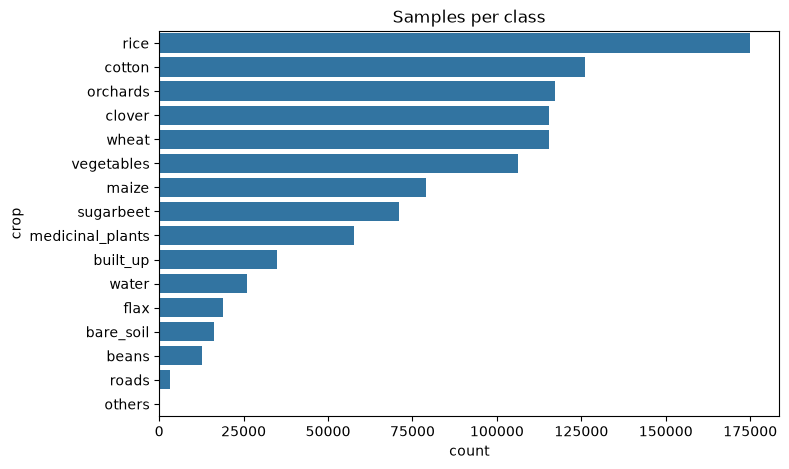

In [9]:
plt.figure(figsize=(8, 5))
sns.countplot(data=samples, y="crop", order=samples["crop"].value_counts().index)
plt.title("Samples per class")
plt.show()

In [10]:
pd.crosstab(samples["crop"], [samples["region"], samples["season"]])

region              SGZ                  ZAN       
season            S2023  S2024  W2324  S2024  W2324
crop                                               
bare_soil          7944   7970     79    315      0
beans                 0      0  12663      0      0
built_up           7387   5067   7356   7515   7545
clover                0      0  59632      0  55825
cotton            59555  59672      0   6767      0
flax                  0      0  18951      0      0
maize              9359  12787      0  56775      0
medicinal_plants      0      0  57631      0      0
orchards            501     38  22223  37684  56808
others                0      0      0     15      0
rice              59735  59643      0  55446      0
roads               894      0      0   2446      0
sugarbeet             0      0  59765      0  11384
vegetables          161   4228    934  56986  43856
water              7948    339   7952   7282   2455
wheat                 0      0  59653      0  55656

The classes are not balanced: rice has 174,824 samples, beans 12,663 and `others` only 15. Each season has its own crops (wheat and clover in winter, rice and cotton in summer), and some classes are very small in one district only. Because of this imbalance the models will be scored with macro-F1, not accuracy.

---
# 2. Data Cleaning

## Check Null (Missing Values)

In [11]:
df.isnull().sum()

sample_id      0
pixel_id       0
region         0
season         0
dekad          0
date           0
n_clear        0
ndvi           0
evi            0
ndwi           0
savi           0
gndvi          0
crop           0
label_doubt    0
dtype: int64

There are no missing values, so nothing is dropped or imputed.

Clouds do leave gaps in a satellite series, but they were filled when the dataset was built, by linear interpolation in time between the clear dates before and after. The column `n_clear` shows where this happened:

In [12]:
interpolated = df["n_clear"] == 0
(interpolated.groupby([df["region"], df["season"]]).mean() * 100).round(1)

region  season
SGZ     S2023     13.0
        S2024      8.1
        W2324     26.8
ZAN     S2024      6.2
        W2324     16.7
Name: n_clear, dtype: float64

Between 6% and 27% of the values are interpolated, most of them in the cloudy winter of Sidi Ghazi. They are kept. A crop grows gradually, so a value between the two neighbouring dates is a good estimate, and it suits a time series better than the mean or median of the column, which would ignore the time of year.

## Detect Duplicate Rows

In [13]:
df.duplicated().sum()

np.int64(0)

There are no duplicated rows, so nothing is dropped.

## Doubtful Labels
Four classes in Sidi Ghazi are flagged with `label_doubt`.

In [14]:
samples[samples["label_doubt"]].groupby(["region", "season", "crop"]).size()

region  season  crop            
SGZ     S2024   bare_soil            7970
                built_up             5067
        W2324   medicinal_plants    57631
                orchards            22223
dtype: int64

One example shows why. Orchards are trees, so they stay green all year, as they do in Zankalon. The pixels called orchards in Sidi Ghazi are bare in December and January and only turn green in March.

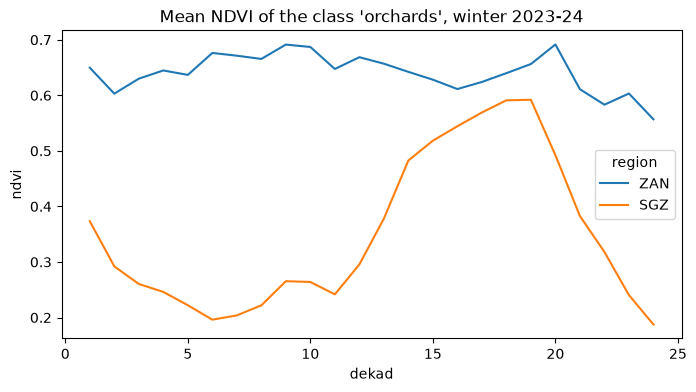

In [15]:
orchards = df[(df["season"] == "W2324") & (df["crop"] == "orchards")]

plt.figure(figsize=(8, 4))
sns.lineplot(data=orchards, x="dekad", y="ndvi", hue="region", errorbar=None)
plt.title("Mean NDVI of the class 'orchards', winter 2023-24")
plt.show()

A field that is bare in winter and green in spring is an annual crop, not an orchard, so the name is wrong. The other three classes contradict their names in the same way: the pixels called built-up and bare soil grow and are harvested like a crop. A wrong label teaches a model the wrong thing, so these 92,891 samples are removed.

## Very Small Classes
A class is counted inside its own district and season, because that is the unit a model is trained and tested on.

In [16]:
class_size = samples.groupby(["region", "season", "crop"])["sample_id"].transform("size")
samples[class_size < 2000].groupby(["region", "season", "crop"]).size()

region  season  crop      
SGZ     S2023   orchards      501
                roads         894
                vegetables    161
        S2024   orchards       38
                water         339
        W2324   bare_soil      79
                vegetables    934
ZAN     S2024   bare_soil     315
                others         15
dtype: int64

Nine classes have fewer than 2,000 samples in their district and season, 3,276 samples in total. That is too few to train on or to score reliably, so they are removed.

## Apply the Cleaning

In [17]:
keep = samples.loc[~samples["label_doubt"] & (class_size >= 2000), "sample_id"]
df_clean = df[df["sample_id"].isin(keep)]

print("Samples before:", df["sample_id"].nunique(), " rows:", len(df))
print("Samples after: ", df_clean["sample_id"].nunique(), " rows:", len(df_clean))

Samples before: 1074827  rows: 22589094


Samples after:  978660  rows: 20372886


96,167 samples (8.9%) are removed. The classes that remain:

In [18]:
df_clean.drop_duplicates("sample_id")["crop"].value_counts()

crop
rice          174824
cotton        125994
clover        115457
wheat         115309
vegetables    105070
orchards       94492
maize          78921
sugarbeet      71149
built_up       29803
water          25637
flax           18951
beans          12663
bare_soil       7944
roads           2446
Name: count, dtype: int64

---
# 3. Outliers

## Check Normal Distribution

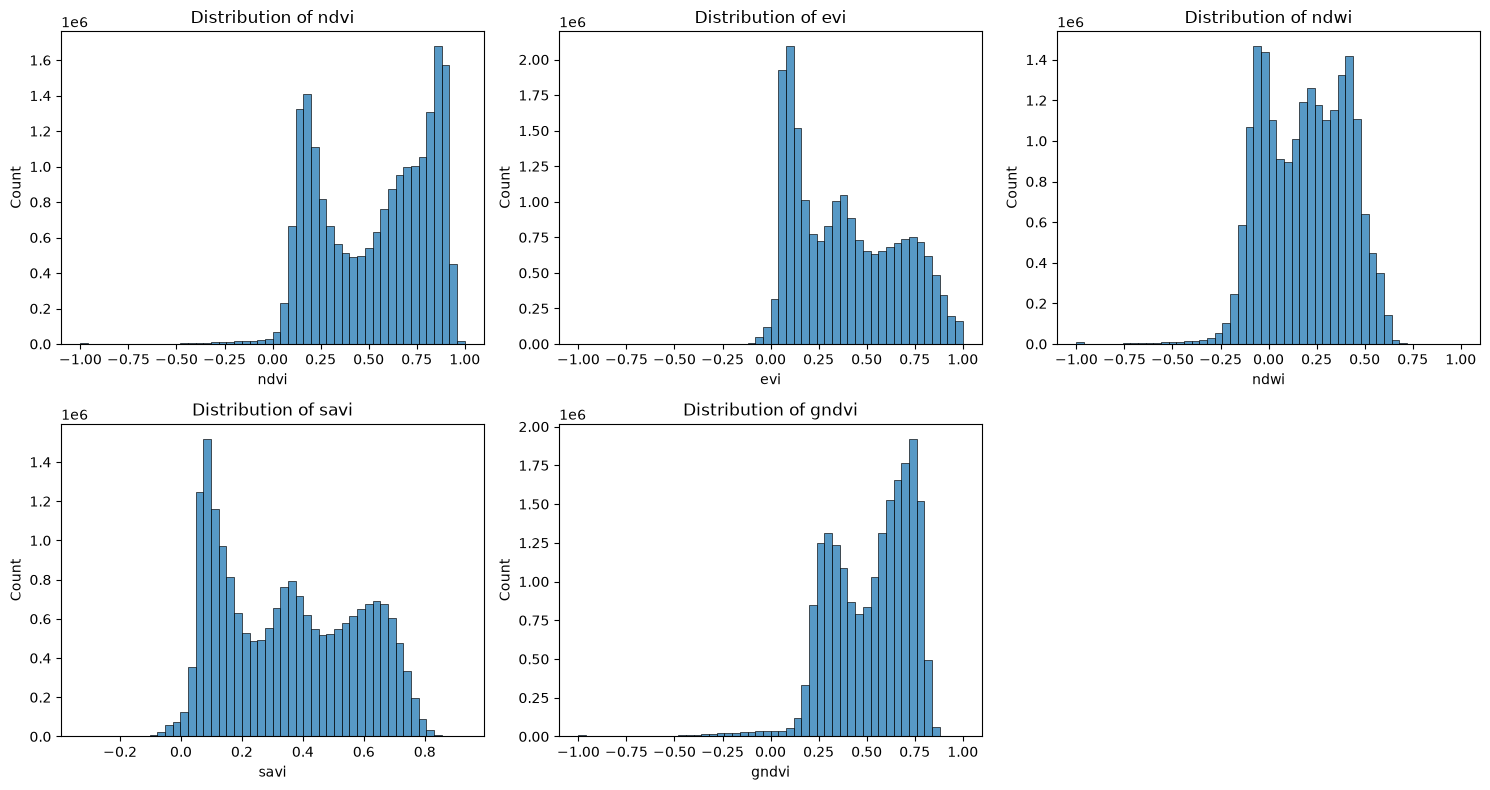

In [19]:
plt.figure(figsize=(15, 8))
for i, feature in enumerate(indices):
    plt.subplot(2, 3, i + 1)
    sns.histplot(df_clean[feature], bins=50)
    plt.title(f"Distribution of {feature}")
plt.tight_layout()
plt.show()

None of the indices is normally distributed. Each has two peaks: a low one for bare soil, before sowing and after harvest, and a high one for a full green crop. Since the data is not normal, the IQR rule is used and not the Z-score.

## Check Outliers (IQR)

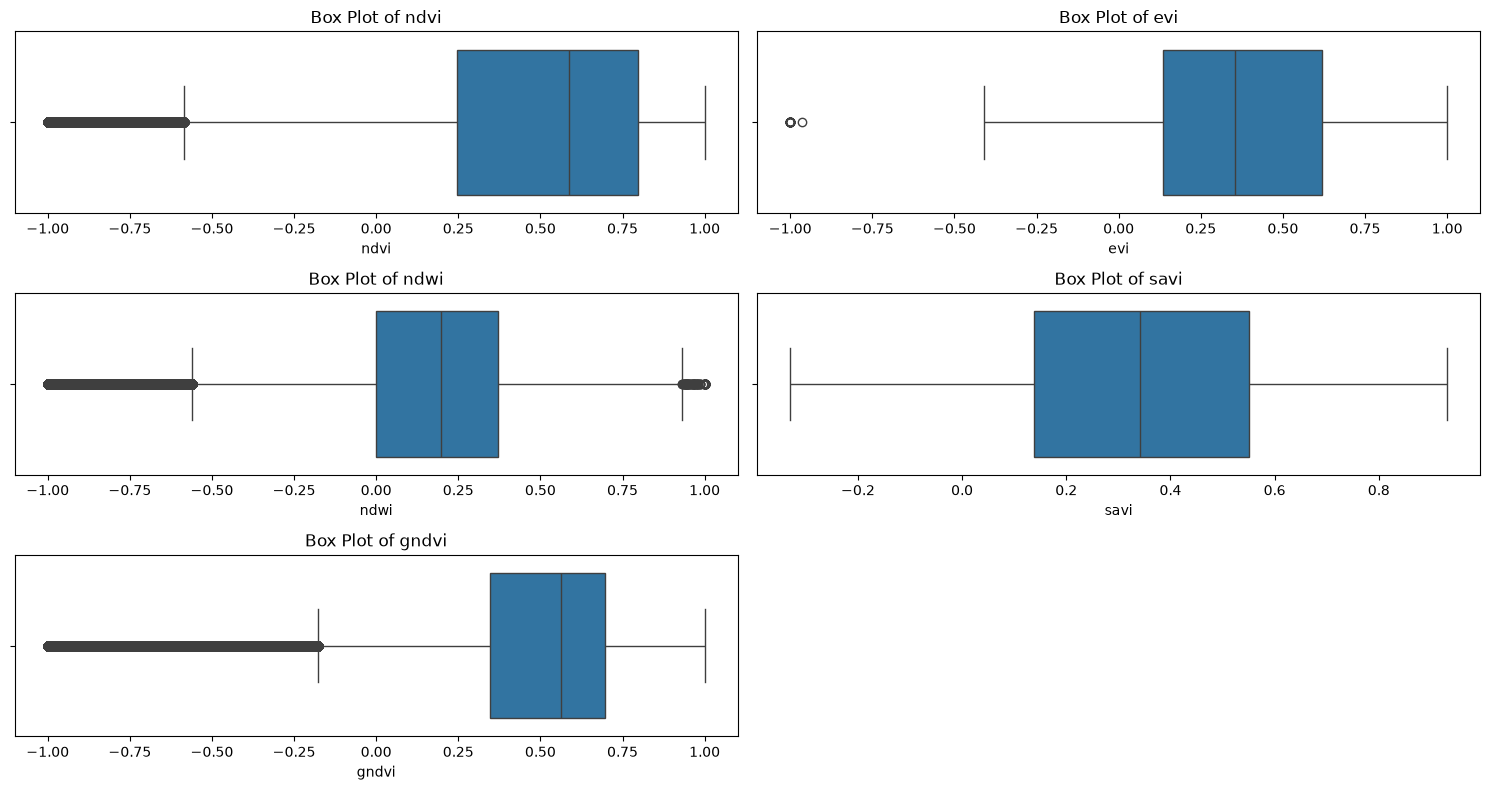

In [20]:
plt.figure(figsize=(15, 8))
for i, feature in enumerate(indices):
    plt.subplot(3, 2, i + 1)
    sns.boxplot(x=df_clean[feature])
    plt.title(f"Box Plot of {feature}")
plt.tight_layout()
plt.show()

In [21]:
for feature in indices:
    Q1 = df_clean[feature].quantile(0.25)
    Q3 = df_clean[feature].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df_clean[(df_clean[feature] < lower) | (df_clean[feature] > upper)]
    print(f"{feature}: limits [{lower:.2f}, {upper:.2f}]  outliers: {len(outliers)} ({len(outliers) / len(df_clean) * 100:.2f}%)")

ndvi: limits [-0.58, 1.63]  outliers: 17030 (0.08%)


evi: limits [-0.59, 1.34]  outliers: 28 (0.00%)


ndwi: limits [-0.56, 0.93]  outliers: 41003 (0.20%)


savi: limits [-0.48, 1.17]  outliers: 0 (0.00%)


gndvi: limits [-0.18, 1.22]  outliers: 147679 (0.72%)


Outliers are rare: 0.72% of the rows for GNDVI, 0.2% or less for the other indices and none for SAVI. Almost all of them are on the low side. The next cell checks which classes the low GNDVI values belong to.

In [22]:
Q1 = df_clean["gndvi"].quantile(0.25)
Q3 = df_clean["gndvi"].quantile(0.75)
lower = Q1 - 1.5 * (Q3 - Q1)

(df_clean.loc[df_clean["gndvi"] < lower, "crop"].value_counts(normalize=True) * 100).round(1).head()

crop
water         96.6
built_up       1.5
vegetables     1.4
wheat          0.3
rice           0.1
Name: proportion, dtype: float64

96.6% of them are water. Water reflects very little near-infrared light, so strongly negative values are its normal signature and not a measurement error.

## Outliers Treatment

**Ignoring.** The outliers are real measurements that belong to one class and help to recognise it. Removing or capping them would erase the information that separates water from crops, so they are left as they are.

---
# 4. Exploratory Analysis
This part uses the clean data. The mean NDVI of every class is computed once for each 10-day period, and the charts below are drawn from this small table.

In [23]:
curves = df_clean.groupby(["region", "season", "crop", "dekad"])["ndvi"].mean().reset_index()
curves.head()

,region,season,crop,dekad,ndvi
0,SGZ,S2023,bare_soil,1,0.282503
1,SGZ,S2023,bare_soil,2,0.282503
2,SGZ,S2023,bare_soil,3,0.262876
3,SGZ,S2023,bare_soil,4,0.253866
4,SGZ,S2023,bare_soil,5,0.255994


## NDVI Curve of Each Crop

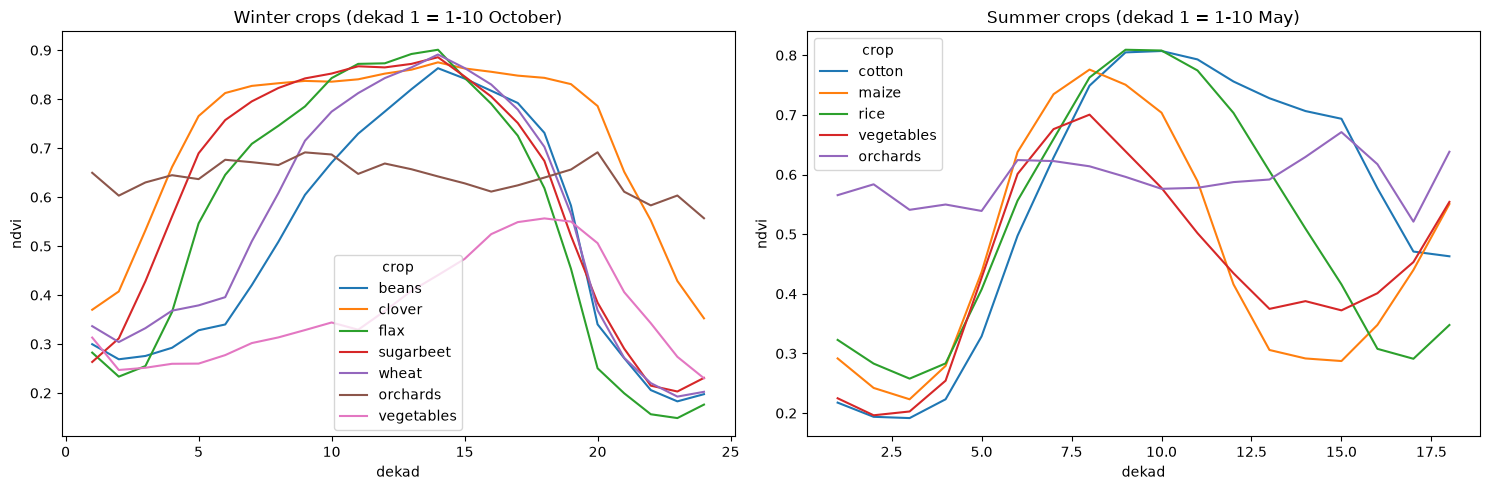

In [24]:
non_crop = ["water", "built_up", "bare_soil", "roads"]
crops = curves[~curves["crop"].isin(non_crop)]
winter = crops[crops["season"] == "W2324"]
summer = crops[crops["season"] != "W2324"]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.lineplot(data=winter, x="dekad", y="ndvi", hue="crop", errorbar=None, ax=axes[0])
axes[0].set_title("Winter crops (dekad 1 = 1-10 October)")
sns.lineplot(data=summer, x="dekad", y="ndvi", hue="crop", errorbar=None, ax=axes[1])
axes[1].set_title("Summer crops (dekad 1 = 1-10 May)")
plt.tight_layout()
plt.show()

Each crop has its own curve. In winter, clover is already green in November and stays green until April, wheat only rises in December and is harvested in April, and orchards stay flat near 0.65 all season. In summer, maize peaks first in July and is dry by September, rice peaks around the start of August, and cotton stays green the longest.

These differences in shape and timing are what a time-series model can learn. The curves are close to each other in the first weeks of a season, which is why recognising a crop early is harder than recognising it at the end.

## The Same Crop in the Two Districts

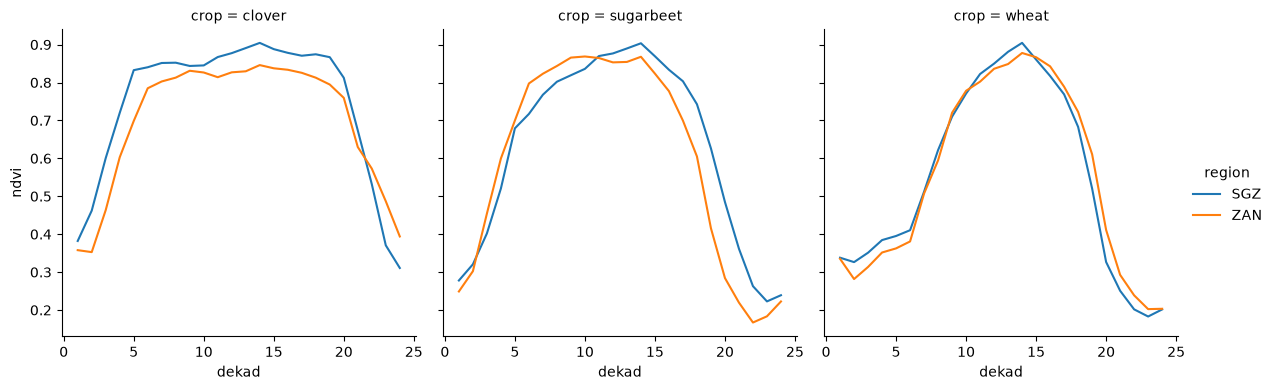

In [25]:
shared = winter[winter["crop"].isin(["wheat", "clover", "sugarbeet"])]

sns.relplot(data=shared, x="dekad", y="ndvi", hue="region", col="crop", kind="line", height=4)
plt.show()

The three winter crops that are common in both districts follow nearly the same curve in each. The average difference in NDVI is 0.03 for wheat and about 0.07 for clover and sugarbeet. Sugarbeet is harvested about two dekads earlier in Zankalon.

## The Same Crop in Two Years

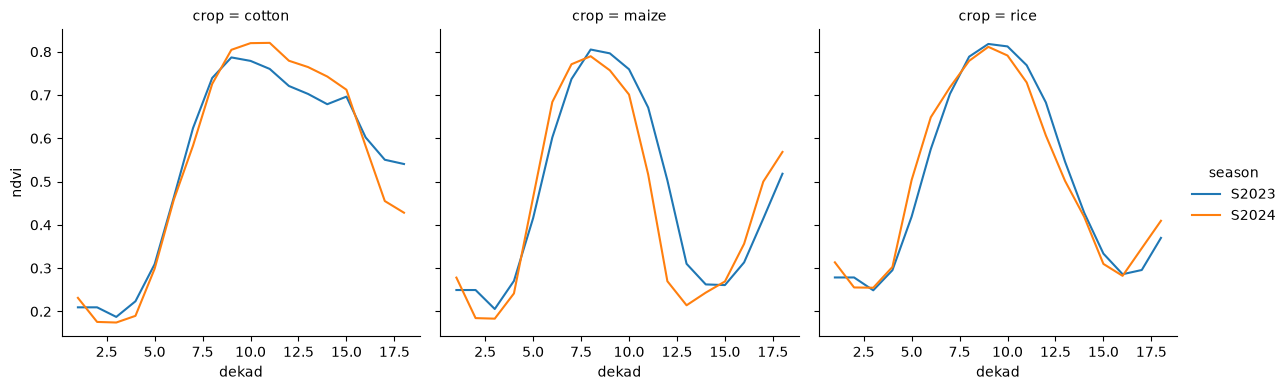

In [26]:
two_years = summer[(summer["region"] == "SGZ") & summer["crop"].isin(["rice", "cotton", "maize"])]

sns.relplot(data=two_years, x="dekad", y="ndvi", hue="season", col="crop", kind="line", height=4)
plt.show()

Sidi Ghazi has two summers. Rice, cotton and maize follow the same curve in 2023 and 2024, with an average difference of 0.03 to 0.06. Maize was harvested about one dekad earlier in 2024.

## Correlation Between the Indices

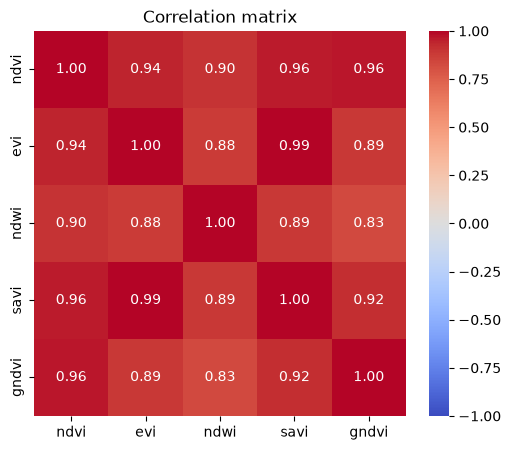

In [27]:
plt.figure(figsize=(6, 5))
sns.heatmap(df_clean[indices].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix")
plt.show()

All five indices are strongly related (0.83 to 0.99), because they all measure green vegetation. EVI and SAVI are almost the same, so one of them adds very little. NDWI is the least related to the others, because it measures the water content of the plant rather than its greenness. Nothing is dropped here; this is kept for choosing the features in the modelling stage.

---
# 5. Summary

| Step | Result | Decision |
|---|---|---|
| Missing values | 0 | nothing to impute |
| Interpolated values | 6% to 27% per district and season | kept, marked by `n_clear` |
| Duplicated rows | 0 | nothing to drop |
| Doubtful labels | 92,891 samples | removed |
| Very small classes | 3,276 samples | removed |
| Outliers (IQR) | under 1%, almost all water | ignored |

The clean dataset has 978,660 samples in 20,372,886 rows. Their ids are saved for the modelling stage.

What the analysis showed:
- every crop has its own NDVI curve, and the curves separate as the season goes on
- the same crop looks nearly the same in the two districts and in the two summers
- the five indices are strongly correlated, EVI and SAVI most of all

In [28]:
df_clean[["sample_id"]].drop_duplicates().to_csv("clean_samples.csv", index=False)